# Entrenamiento y comparación de baselines — Galaxy Zoo (elíptica vs. espiral)

Este notebook consume los splits persistidos en `data/galaxy_zoo_challenge/processed/`
(generados por `src/data/make_splits.py`, a partir de `src/data/dataset.py`) para correr
de punta a punta el entrenamiento y la comparación de los baselines de sklearn definidos en
`src/models/sklearn_baselines.py`: Regresión Logística, KNN, Random Forest,
SVM lineal e HistGradientBoosting.

A diferencia de `src/train_baselines.py` (que submuestrea el train set para ir
rápido), este notebook corre sobre los splits **completos** y deja registro
visual/reproducible de la comparación.

**Fuente de los datos:** `data/galaxy_zoo_challenge/processed/train.csv`, `val.csv`, `test.csv`
(índices `GalaxyID` + vote fractions de Task 1 + `label`; no las imágenes).

In [1]:
# importaciones de sistema
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# importaciones de terceros
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay, confusion_matrix

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)


In [2]:
# configuración e imports del proyecto
from src.config import RANDOM_SEED
from src.data.dataset import load_splits_from_csv
from src.data.features import extract_pixel_features
from src.evaluate import evaluate_binary_classifier
from src.models.sklearn_baselines import get_baseline_models

np.random.seed(RANDOM_SEED)


## Carga de los splits desde CSV

Los índices de `GalaxyID`/`label` ya quedaron persistidos en
`data/galaxy_zoo_challenge/processed/{train,val,test}.csv` por `src/data/make_splits.py`
— no se rederiva el split acá, solo se cargan los tres CSV.

In [3]:
train_df, val_df, test_df = load_splits_from_csv()

for name, split in [('train', train_df), ('val', val_df), ('test', test_df)]:
    props = split['label'].value_counts(normalize=True)
    print(f"{name:6s} n={len(split):6d}  elliptical={props.get('elliptical', 0):.1%}  spiral={props.get('spiral', 0):.1%}")


train  n= 16991  elliptical=33.5%  spiral=66.5%
val    n=  3641  elliptical=33.5%  spiral=66.5%
test   n=  3641  elliptical=33.5%  spiral=66.5%


## Extracción de features de píxeles

Cada imagen se reescala a 64x64 px y se normaliza a [0, 1] (`src/data/features.py`).
Es una representación simple (píxeles planos, sin recorte adaptativo ni HOG):
sirve de piso de comparación antes de la CNN/ResNet de la fase 1 (ver `README.md`,
sección Arquitectura del modelo).

Se procesan los tres splits **completos** — con las ~24 mil imágenes del
subconjunto limpio esto toma un par de minutos.

In [4]:
t0 = time.time()
X_train, y_train = extract_pixel_features(train_df)
X_val, y_val = extract_pixel_features(val_df)
X_test, y_test = extract_pixel_features(test_df)
print(f"X_train: {X_train.shape}  X_val: {X_val.shape}  X_test: {X_test.shape}")
print(f"Tiempo de extracción: {time.time() - t0:.1f}s")


X_train: (16991, 12288)  X_val: (3641, 12288)  X_test: (3641, 12288)
Tiempo de extracción: 97.0s


## Entrenamiento y comparación de modelos

Cinco baselines de sklearn (`src/models/sklearn_baselines.py`), todos con el
mismo pipeline `StandardScaler` + `PCA` para que la comparación sea justa. Se
entrena sobre el split completo de `train` y se evalúa sobre `val` (el split
de `test` se reserva para el final, una vez elegido el mejor modelo).

In [5]:
models = get_baseline_models(seed=RANDOM_SEED)
results = []
val_predictions = {}  # nombre -> (y_pred, y_proba)

for name, pipeline in models.items():
    t0 = time.time()
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)
    y_proba = pipeline.predict_proba(X_val)[:, 1]
    elapsed = time.time() - t0

    val_predictions[name] = (y_pred, y_proba)
    metrics = evaluate_binary_classifier(y_val, y_pred, y_proba)
    report = metrics['report']
    results.append({
        'model': name,
        'accuracy': metrics['accuracy'],
        'roc_auc': metrics['roc_auc'],
        'precision_spiral': report['1']['precision'],
        'recall_spiral': report['1']['recall'],
        'f1_spiral': report['1']['f1-score'],
        'precision_elliptical': report['0']['precision'],
        'recall_elliptical': report['0']['recall'],
        'f1_elliptical': report['0']['f1-score'],
        'train_seconds': elapsed,
    })
    print(f"{name:24s} accuracy={metrics['accuracy']:.4f}  roc_auc={metrics['roc_auc']:.4f}  ({elapsed:.1f}s)")

summary = pd.DataFrame(results).sort_values('roc_auc', ascending=False).reset_index(drop=True)
summary


logistic_regression      accuracy=0.8006  roc_auc=0.8645  (3.9s)


knn                      accuracy=0.8250  roc_auc=0.8794  (5.0s)


random_forest            accuracy=0.8385  roc_auc=0.9033  (5.0s)


svm_linear               accuracy=0.8075  roc_auc=0.8640  (3.7s)


hist_gradient_boosting   accuracy=0.8701  roc_auc=0.9320  (12.9s)


,model,accuracy,roc_auc,precision_spiral,recall_spiral,f1_spiral,precision_elliptical,recall_elliptical,f1_elliptical,train_seconds
0,hist_gradient_boosting,0.870091,0.932017,0.913413,0.888889,0.900984,0.790661,0.832787,0.811178,12.867333
1,random_forest,0.838506,0.903280,0.842873,0.930607,0.884570,0.826446,0.655738,0.731261,4.975994
2,knn,0.825048,0.879350,0.844402,0.903346,0.872880,0.777355,0.669672,0.719507,5.014975
3,logistic_regression,0.800604,0.864548,0.895474,0.792648,0.840929,0.664887,0.816393,0.732892,3.852995
4,svm_linear,0.807470,0.864039,0.821135,0.908302,0.862522,0.769470,0.607377,0.678882,3.696396


## Gráficas de desempeño

Comparación visual de los cinco modelos sobre el split de validación:
accuracy/ROC-AUC, F1 por clase, curvas ROC y matrices de confusión.

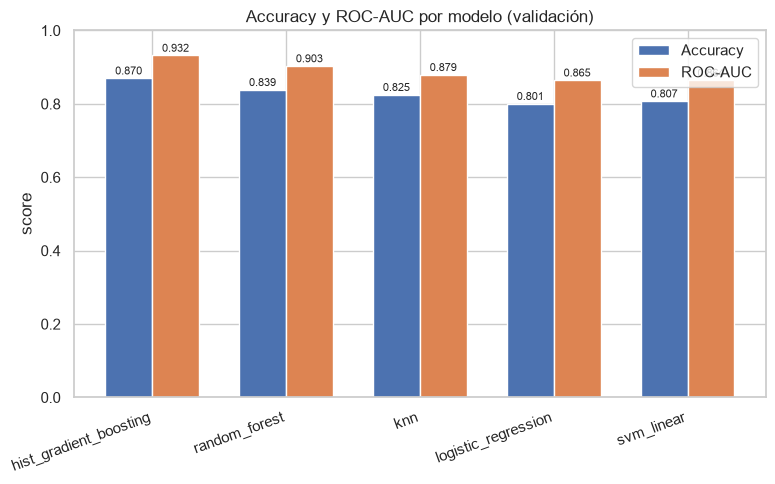

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(summary))
width = 0.35
ax.bar(x - width/2, summary['accuracy'], width, label='Accuracy', color='#4C72B0')
ax.bar(x + width/2, summary['roc_auc'], width, label='ROC-AUC', color='#DD8452')
ax.set_xticks(x)
ax.set_xticklabels(summary['model'], rotation=20, ha='right')
ax.set_ylim(0, 1)
ax.set_ylabel('score')
ax.set_title('Accuracy y ROC-AUC por modelo (validación)')
ax.legend()
for i, (acc, auc) in enumerate(zip(summary['accuracy'], summary['roc_auc'])):
    ax.text(i - width/2, acc + 0.01, f"{acc:.3f}", ha='center', fontsize=8)
    ax.text(i + width/2, auc + 0.01, f"{auc:.3f}", ha='center', fontsize=8)
plt.tight_layout()
plt.show()


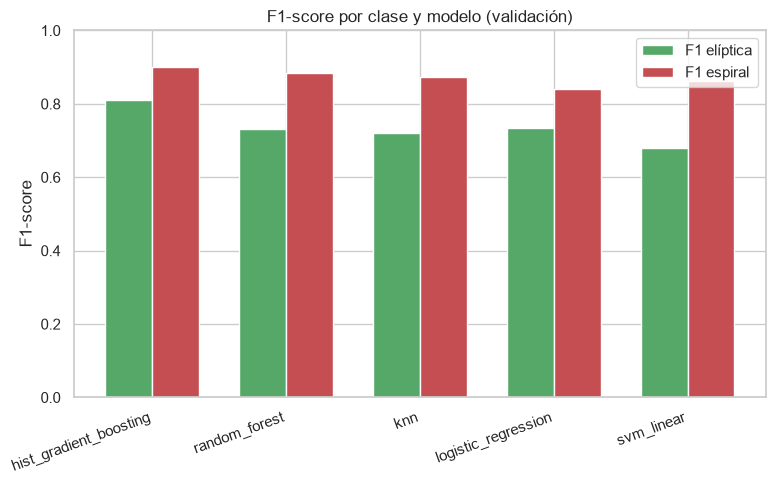

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, summary['f1_elliptical'], width, label='F1 elíptica', color='#55A868')
ax.bar(x + width/2, summary['f1_spiral'], width, label='F1 espiral', color='#C44E52')
ax.set_xticks(x)
ax.set_xticklabels(summary['model'], rotation=20, ha='right')
ax.set_ylim(0, 1)
ax.set_ylabel('F1-score')
ax.set_title('F1-score por clase y modelo (validación)')
ax.legend()
plt.tight_layout()
plt.show()


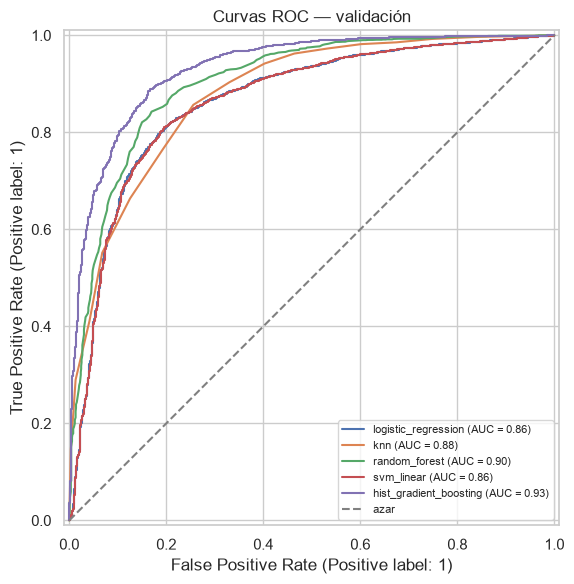

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, (y_pred, y_proba) in val_predictions.items():
    RocCurveDisplay.from_predictions(y_val, y_proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='azar')
ax.set_title('Curvas ROC — validación')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


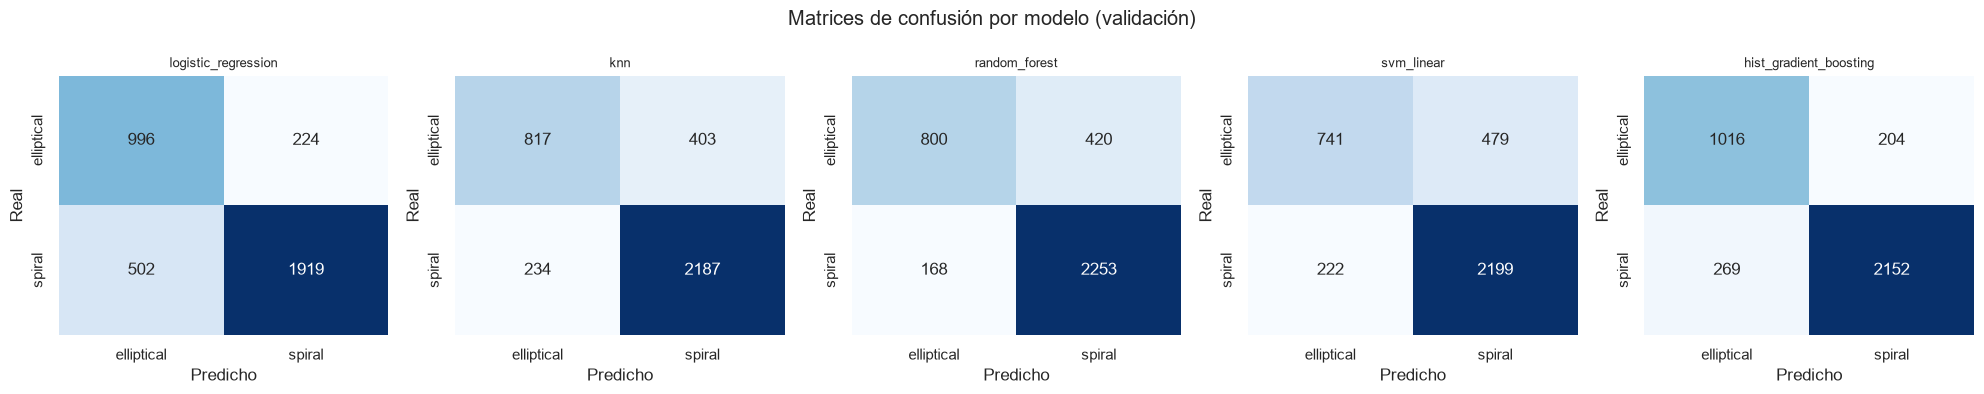

In [9]:
labels_order = [0, 1]
labels_names = ['elliptical', 'spiral']

fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4))
for ax, (name, (y_pred, _)) in zip(axes, val_predictions.items()):
    cm = confusion_matrix(y_val, y_pred, labels=labels_order)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels_names, yticklabels=labels_names, ax=ax)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
fig.suptitle('Matrices de confusión por modelo (validación)')
plt.tight_layout()
plt.show()


## Evaluación final del mejor modelo sobre test

El split de `test` no se usó para elegir entre modelos (eso lo hizo `val`):
se evalúa una sola vez, con el modelo ganador, para reportar una estimación
no sesgada del desempeño final.

In [10]:
best_name = summary.iloc[0]['model']
best_model = models[best_name]
print(f"Mejor modelo (por ROC-AUC en validación): {best_name}")

y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]
test_metrics = evaluate_binary_classifier(y_test, y_test_pred, y_test_proba)

print(f"\nTest -- accuracy: {test_metrics['accuracy']:.4f}  ROC-AUC: {test_metrics['roc_auc']:.4f}")
print("\nMatriz de confusión (test):")
print(test_metrics['confusion_matrix'])
print("\nReporte por clase:")
pd.DataFrame(test_metrics['report']).T


Mejor modelo (por ROC-AUC en validación): hist_gradient_boosting

Test -- accuracy: 0.8695  ROC-AUC: 0.9366

Matriz de confusión (test):
[[1020  200]
 [ 275 2146]]

Reporte por clase:


,precision,recall,f1-score,support
0,0.787645,0.836066,0.811133,1220.000000
1,0.914749,0.886411,0.900357,2421.000000
accuracy,0.869541,0.869541,0.869541,0.869541
macro avg,0.851197,0.861238,0.855745,3641.000000
weighted avg,0.872160,0.869541,0.870460,3641.000000


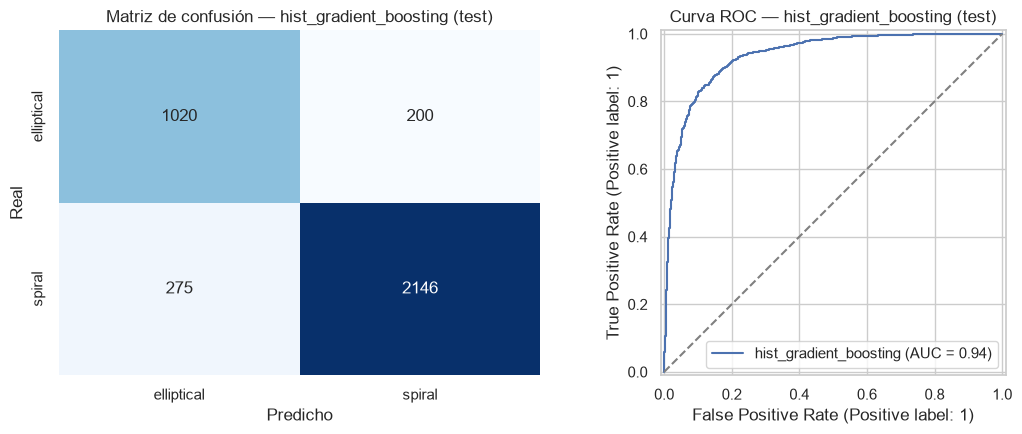

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(test_metrics['confusion_matrix'], annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=labels_names, yticklabels=labels_names, ax=axes[0])
axes[0].set_title(f'Matriz de confusión — {best_name} (test)')
axes[0].set_xlabel('Predicho')
axes[0].set_ylabel('Real')

RocCurveDisplay.from_predictions(y_test, y_test_proba, name=best_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title(f'Curva ROC — {best_name} (test)')

plt.tight_layout()
plt.show()


## Conclusiones

- Comparación completa (splits `train`/`val` completos, sin submuestreo) de 5
  baselines clásicos de sklearn sobre píxeles aplanados 64x64 + PCA(150).
- El modelo ganador en validación (ver tabla y gráficas arriba) se reevaluó
  una única vez sobre `test`, para una estimación no sesgada del desempeño.
- Referencia de literatura (ver `README.md`, sección Métricas de evaluación):
  ~94.5–99% OA en binario con CNN/transfer learning (Dieleman et al. 2015,
  Barchi et al. 2020). Estos baselines, por diseño, deberían quedar por
  debajo de ese rango — confirman que el pipeline de datos funciona y fijan el
  piso que la CNN/ResNet50 de la fase 1 tiene que superar.
- Pendiente: implementar el baseline CNN desde cero (ver
  `notebook/cnn_baseline.ipynb`) y, luego, transfer learning con
  ResNet50/ResNet50V2 (ver `README.md`, sección Arquitectura del modelo),
  reutilizando los mismos splits de `data/galaxy_zoo_challenge/processed/` para que
  la comparación sea directa.

<!-- Autor: Alexander Carreño Correa (alexandercorreacorrea1997@gmail.com) -->